<a href="https://colab.research.google.com/github/dusandraq/Coding-Projects/blob/main/HousePricesHWAI.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
   square_feet  num_bedrooms  num_bathrooms  garage_space  house_age  price
0         1360             1              3             1         43    454
1         4272             1              2             1         50    295
2         3592             3              2             0         23    791
3          966             5              2             1         44    640
4         4926             4              1             0         38    710
square_feet      0
num_bedrooms     0
num_bathrooms    0
garage_space     0
house_age        0
price            0
dtype: int64
Mean Squared Error: 81130.68
R-squared Score: -0.0624


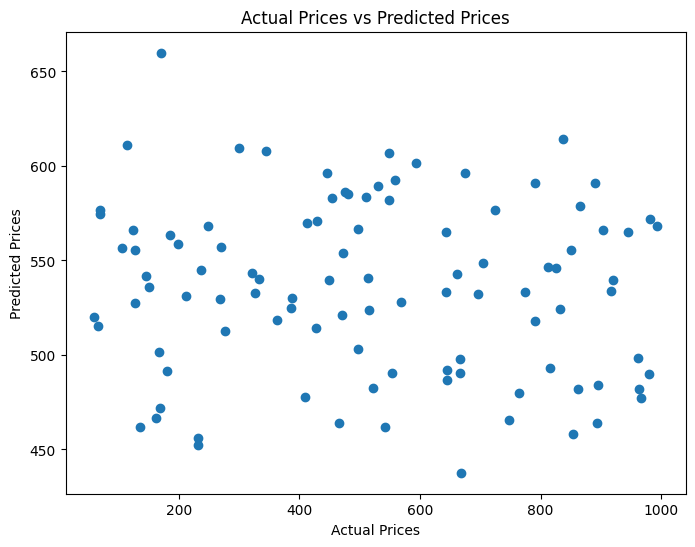

In [14]:
import pandas as pd #needed for dataframe
import numpy as np #needed for min and max
from sklearn.model_selection import train_test_split #needed for splitting the dataset
from sklearn.preprocessing import StandardScaler #needed for normalizing features
from sklearn.linear_model import LinearRegression #needed for linear regression model
from sklearn.metrics import mean_squared_error, r2_score #needed for evaluation metrics
import matplotlib.pyplot as plt #needed for scatter plot


#connect my drive to load in house_prices file
from google.colab import drive
drive.mount('/content/drive')

#1. Load in my dataset
df = pd.read_csv('/content/drive/MyDrive/house_prices.csv')

#2. Check that the file loaded
print(df.head())

#3. Check if we have a missing value sum and drop them if we do.
print(df.isnull().sum())
#no null values showing.

#4. Seperation of target variable
X = df[['square_feet', 'num_bedrooms', 'num_bathrooms', 'garage_space', 'house_age']]
y = df['price']

#5. Spliting the dataset
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

#6. Normalizing features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

#7. Create a Linear Regression model
model = LinearRegression()
model.fit(X_train_scaled, y_train)

#8. Using MSE and R-squared score.
mse = mean_squared_error(y_test, model.predict(X_test_scaled))
r2 = r2_score(y_test, model.predict(X_test_scaled))

print(f"Mean Squared Error: {mse:.2f}")
print(f"R-squared Score: {r2:.4f}")

#9. Making the scatter plot
plt.figure(figsize = (8,6))
plt.scatter(y_test, model.predict(X_test_scaled))
plt.xlabel('Actual Prices')
plt.ylabel('Predicted Prices')
plt.title('Actual Prices vs Predicted Prices')
plt.show()







